# TP guidé — Prévision de consommation électrique sans fuite de données

**Parcours provisoire, à adapter à l'énoncé.** Le dossier contient les données UCI
`household_power_consumption.txt`, mais aucun énoncé. Les choix ci-dessous sont donc
des hypothèses de travail, et non des exigences attribuées au professeur.

**Objectif :** prévoir la puissance active moyenne de la prochaine heure, en **kW**.
Nous allons comprendre les données, construire des variables disponibles au moment
de la prévision, comparer des modèles et réserver une période finale pour une mesure honnête.

Tout le travail est dans ce notebook : explications, code, graphiques et réponses à rédiger.
Aucun module du dossier `src` n'est nécessaire.

| Séance | Travail | Critère pour passer à la suite |
|---|---|---|
| 1 | Étapes 0 à 4 : environnement, cible, qualité, découpage | Expliquer exactement ce qui est prévu et quand |
| 2 | Étapes 5 à 7 : exploration, variables et contrôles | Justifier la disponibilité de chaque variable |
| 3 | Étapes 8 à 11 : références, modèles et validation | Comparer MAE, stabilité et temps de calcul |
| 4 | Étapes 12 à 14 : décision, test final et rédaction | Figer les choix avant de consulter le test |

**Comment travailler :** exécuter les cellules dans l'ordre avec `Maj + Entrée`.
Après chaque étape, compléter la cellule Markdown « À toi » avec ses propres mots.
En cas de modification d'une étape amont, redémarrer le noyau et réexécuter le parcours.
Le test final est désactivé au départ ; il n'est pas nécessaire pour apprendre et améliorer les modèles.


## 0 — Ouvrir le notebook et choisir le bon environnement

Dans VS Code, ouvrir ce fichier et sélectionner le noyau Python du dossier `.venv` du projet.
Dans JupyterLab, choisir le noyau correspondant à cet environnement.
Pour lancer JupyterLab depuis la racine du projet, la commande est
`.venv/bin/python -m jupyter lab`.

La cellule suivante affiche le Python réellement utilisé. Si les imports de l'étape 1 échouent,
décommenter et exécuter la ligne `%pip`, puis redémarrer le noyau. Installer les dépendances
une fois, pas à chaque expérience. Un environnement Python 3.12 ou plus récent convient
si les bibliothèques requises y sont disponibles.


In [1]:
import sys
print("Python du noyau :", sys.executable)
# Installation uniquement si nécessaire dans le noyau sélectionné :
# %pip install numpy pandas matplotlib scikit-learn ipykernel


Python du noyau : /Users/rahou/Desktop/Machine learning/electric-load-forecast/.venv/bin/python


## 1 — Fixer le contrat de prévision avant de regarder les résultats

Une **fuite de données** apparaît lorsqu'une information indisponible à l'instant de
prévision influence les variables, les transformations ou le choix du modèle.

Une ligne datée **10:00** représentera la puissance moyenne de **[09:00, 10:00)**.
Elle devient connue à 10:00, en supposant que le compteur transmet sans retard.
Avec `HORIZON_H = 1`, on prévoit cette ligne à **09:00**, après réception de l'heure précédente.
Les variables issues des mesures doivent donc venir de 09:00 ou d'avant.

```text
mesures [08:00, 09:00) → moyenne connue à 09:00 → prévision de [09:00, 10:00)
                                             origine                 cible à 10:00
```

Le modèle reste fixe pendant un bloc d'évaluation, tandis que l'historique mesuré se met
à jour à chaque heure. C'est une suite de prévisions à horizon fixe, avec observations reçues
au fil du temps. Une prévision des 24 prochaines heures émises toutes ensemble nécessite
un autre protocole. Passer `HORIZON_H` à 24 signifie ici prévoir **une heure située 24 heures
plus tard**, à chaque nouvelle origine ; cela ne produit pas les 24 horizons d'un seul coup.

**Métrique principale : MAE en kW** ; plus petite = meilleure. RMSE et biais complètent
l'analyse. La RMSE donne davantage de poids aux grandes erreurs. Le biais est ici la
moyenne de `prévision − observation`. La MAPE peut être instable lorsque la consommation
est proche de zéro.

Les dates ci-dessous sont fixées avant l'analyse des valeurs. Elles pourront être remplacées
par celles imposées par l'énoncé, avant toute sélection de modèle.


In [2]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
HORIZON_H = 1
VALID_START = pd.Timestamp("2010-01-01 00:00")
TEST_START = pd.Timestamp("2010-07-01 00:00")
MIN_VALID_MINUTES = 60  # Une cible n'est retenue que si l'heure est complète.
N_FOLDS = 3
CV_DAYS = 90
RUN_SEARCH = False     # Activer après la première comparaison.
RUN_FINAL_TEST = False # Activer uniquement après avoir figé les choix à l'étape 12.
N_THREADS = 2

assert isinstance(HORIZON_H, int) and 1 <= HORIZON_H <= 168
assert MIN_VALID_MINUTES == 60, "Ce parcours utilise des heures entièrement observées."
DELTA = pd.Timedelta(hours=HORIZON_H)
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.2})

roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p / "data/raw/household_power_consumption.txt").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le projet contenant data/raw/household_power_consumption.txt.")
DATA_PATH = ROOT / "data/raw/household_power_consumption.txt"
versions = {name: importlib.metadata.version(name)
            for name in ["numpy", "pandas", "matplotlib", "scikit-learn", "ipykernel"]}
display(pd.Series({"Python": platform.python_version(), **versions}, name="Version"))
print("Projet :", ROOT)


Python          3.14.0
numpy            2.5.4
pandas           3.0.6
matplotlib      3.11.2
scikit-learn     1.9.1
ipykernel        7.4.0
Name: Version, dtype: str

Projet : /Users/rahou/Desktop/Machine learning/electric-load-forecast


**À toi — contrat à compléter avant de continuer**

- Énoncé du TP / contraintes du professeur : …
- À quel instant ma prévision est-elle émise ? …
- Quelle grandeur est prévue, à quelle fréquence et dans quelle unité ? …
- Le compteur transmet-il immédiatement ou avec un délai ? …
- Pourquoi ai-je choisi MAE comme métrique principale ? …


## 2 — Lire les données et contrôler leur structure

On ne charge que la date, l'heure et `Global_active_power` : cela limite la mémoire et
évite d'introduire sans réfléchir des mesures contemporaines de la cible.
Le séparateur est `;`, les dates sont jour/mois/année et `?` signale une valeur absente.
Un doublon de timestamp bloque le parcours : il faut comprendre son origine avant de l'agréger.

Ces mesures proviennent d'un foyer à Sceaux et couvrent presque quatre ans. La puissance
active est exprimée en kW ; les sous-compteurs utilisent des Wh. Source :
[UCI, Hebrail et Berard](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption).
Les horodatages du fichier n'indiquent pas de fuseau. Nous conservons leur horloge telle
quelle ; une application réelle devrait clarifier fuseau, changements d'heure et délais de réception.


In [3]:
raw = pd.read_csv(
    DATA_PATH, sep=";", usecols=["Date", "Time", "Global_active_power"],
    na_values=["?", ""], dtype={"Global_active_power": "float64"},
)
timestamp = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S", errors="raise")
minute = pd.Series(raw["Global_active_power"].to_numpy(), index=timestamp, name="power_kw").sort_index()
assert minute.index.is_unique, "Doublons temporels : examiner la source avant de continuer."
assert (minute.index == minute.index.floor("min")).all(), "Dates non alignées sur la minute."
full_minute_index = pd.date_range(minute.index.min(), minute.index.max(), freq="min")
print(f"Lignes lues : {len(minute):,} ; timestamps absents : {len(full_minute_index.difference(minute.index)):,}")
print("Étendue temporelle :", minute.index.min(), "→", minute.index.max())
minute = minute.reindex(full_minute_index)
assert (minute.loc[minute.index < VALID_START].dropna() >= 0).all(), "Puissance négative dans l'entraînement."
display(minute.head().to_frame())
del raw, timestamp, full_minute_index


Lignes lues : 2,075,259 ; timestamps absents : 0
Étendue temporelle : 2006-12-16 17:24:00 → 2010-11-26 21:02:00


,power_kw
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


## 3 — Construire une cible horaire fiable

La moyenne de 60 mesures de puissance reste une puissance en **kW**. L'énergie sur une heure
complète vaut cette moyenne multipliée par 1 h, en **kWh** ; les unités restent distinctes.

Une heure incomplète reçoit une cible `NaN`. On ne fabrique pas la vérité à prévoir par
interpolation. Les timestamps restent présents : `shift(24)` doit toujours représenter 24 heures.
La première et la dernière heure peuvent être partielles.

L'agrégation est déterministe et utilise seulement les minutes de l'heure concernée. Son
étiquette est placée à la **fin** de l'heure. Le décalage des variables à l'étape 6 empêchera
de lire cette heure avant sa fin. Les statistiques exploratoires restent limitées à l'entraînement.


In [4]:
hourly = minute.resample("h", closed="left", label="right").agg(["mean", "count"])
hourly.columns = ["power_kw", "n_valid_minutes"]
hourly = hourly.asfreq("h")
hourly.loc[hourly["n_valid_minutes"] < MIN_VALID_MINUTES, "power_kw"] = np.nan
y = hourly["power_kw"].rename("target_kw")
assert y.index.equals(pd.date_range(y.index.min(), y.index.max(), freq="h"))
assert y.index.min() < VALID_START < TEST_START < y.index.max()
print(f"Grille horaire : {len(hourly):,} lignes.")
display(hourly.loc[hourly.index < VALID_START].head())
del minute  # Libérer les données minute ; l'analyse continue sur la grille horaire.


Grille horaire : 34,589 lignes.


,power_kw,n_valid_minutes
2006-12-16 18:00:00,NaN,36
2006-12-16 19:00:00,3.632200,60
2006-12-16 20:00:00,3.400233,60
2006-12-16 21:00:00,3.268567,60
2006-12-16 22:00:00,3.056467,60


## 4 — Séparer le temps et protéger le test final

On utilise trois rôles distincts :

| Période de cible | Usage |
|---|---|
| Avant janvier 2010, avec purge éventuelle | Exploration et validation croisée chronologique pour choisir les paramètres |
| Janvier à juin 2010, limitée aux observations disponibles avant le test | Validation de développement, graphiques d'erreur |
| À partir de juillet 2010 | Test final après gel des choix |

Pour une première cible de validation `v`, l'entraînement peut utiliser uniquement
des cibles datées **au plus tard `v − H`**. Nous supposons entraînement et réception
instantanés ; un délai réel exigerait une marge supplémentaire.
Sur une grille horaire, cela retire `H − 1` lignes entre entraînement et validation.
Avec `H = 1`, aucune heure supplémentaire n'est à retirer. Nous utilisons des dates explicites
pour que les valeurs manquantes ne faussent pas cette durée.

Un historique de 168 heures n'impose pas, à lui seul, de supprimer 168 heures : cet historique
est autorisé dès lors qu'il est réellement disponible à l'origine de prévision.


In [5]:
train_cutoff = VALID_START - DELTA
final_fit_cutoff = TEST_START - DELTA
train_time = y.index <= train_cutoff
valid_time = (y.index >= VALID_START) & (y.index < TEST_START) & (y.index <= final_fit_cutoff)
test_time = y.index >= TEST_START

display(pd.DataFrame([
    {"rôle": "entraînement / CV", "début": y.index.min(), "fin autorisée": train_cutoff},
    {"rôle": "validation", "début": VALID_START, "fin autorisée": min(TEST_START - pd.Timedelta(hours=1), final_fit_cutoff)},
    {"rôle": "test final réservé", "début": TEST_START, "fin autorisée": y.index.max()},
]))
assert y.index[train_time].max() <= VALID_START - DELTA
assert y.index[valid_time].max() <= TEST_START - DELTA


,rôle,début,fin autorisée
0,entraînement / CV,2006-12-16 18:00:00,2009-12-31 23:00:00
1,validation,2010-01-01 00:00:00,2010-06-30 23:00:00
2,test final réservé,2010-07-01 00:00:00,2010-11-26 22:00:00


## 5 — Explorer uniquement l'entraînement

On étudie les cycles horaires, hebdomadaires et annuels pour proposer des variables.
Les pointes de consommation ne sont pas supprimées automatiquement : elles peuvent être réelles.
Les moyennes journalières ci-dessous servent à visualiser, pas à construire une nouvelle cible.


heures dans la grille         26670.000000
heures avec cible complète    26476.000000
heures exclues (%)                0.727409
puissance moyenne (kW)            1.099071
quantile 95 % (kW)                2.940583
Name: Entraînement, dtype: float64

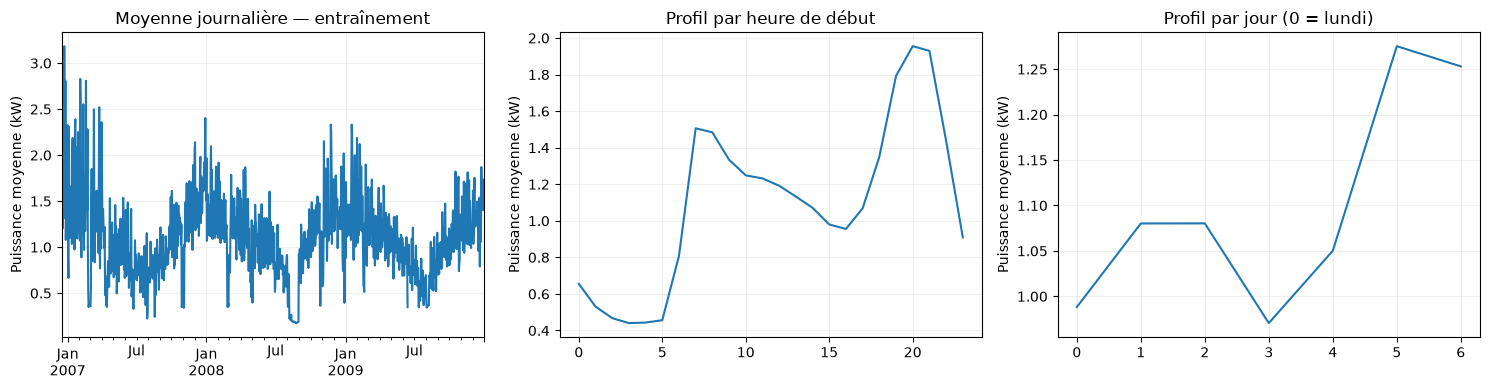

In [6]:
y_train_eda = y.loc[train_time]
display(pd.Series({
    "heures dans la grille": len(y_train_eda),
    "heures avec cible complète": y_train_eda.notna().sum(),
    "heures exclues (%)": 100 * y_train_eda.isna().mean(),
    "puissance moyenne (kW)": y_train_eda.mean(),
    "quantile 95 % (kW)": y_train_eda.quantile(0.95),
}, name="Entraînement"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y_train_eda.resample("D").mean().plot(ax=axes[0], title="Moyenne journalière — entraînement")
period_start = y_train_eda.index - pd.Timedelta(hours=1)
y_train_eda.groupby(period_start.hour).mean().plot(ax=axes[1], title="Profil par heure de début")
y_train_eda.groupby(period_start.dayofweek).mean().plot(ax=axes[2], title="Profil par jour (0 = lundi)")
for ax in axes:
    ax.set_ylabel("Puissance moyenne (kW)")
plt.tight_layout()
plt.show()


**À toi — interpréter avant de modéliser**

Quels cycles observes-tu ? À quelles heures la puissance moyenne est-elle la plus élevée ?
Quelle part de l'entraînement possède une cible complète ? Pourquoi un découpage aléatoire
ne simulerait-il pas correctement une prévision du futur ?

**Mes observations :** …


## 6 — Fabriquer les variables sans regarder le futur

Pour prédire la cible `y[t]`, l'origine est `t − H`.

| Variable | Information utilisée | Disponible à l'origine ? |
|---|---|---|
| Dernière puissance | `y[t − H]` | Oui, sous l'hypothèse de réception immédiate |
| Retard journalier | `y[t − 24]` pour H ≤ 24 | Oui |
| Retard hebdomadaire | `y[t − 168]` pour H ≤ 168 | Oui |
| Moyenne passée | Fenêtre terminée à `t − H` | Oui |
| Heure, jour, mois de la période cible | Calendrier | Oui |
| Intensité ou sous-compteurs de l'heure cible | Mesures de l'heure à prévoir | Non |
| Météo observée pendant l'heure cible | Observation future | Non ; il faudrait la prévision météo archivée à l'origine |

La règle de code à retenir est **décaler puis calculer** :
`y.shift(H).rolling(24).mean()`.
Les moyennes sont calculées sur les observations disponibles de la fenêtre ; leur nombre
est aussi fourni. Les autres valeurs manquantes seront traitées dans chaque entraînement.
Les cycles calendrier sont codés en sinus/cosinus pour rapprocher 23 h et 0 h.


In [7]:
def make_features(series, horizon):
    assert horizon >= 1
    assert series.index.equals(pd.date_range(series.index.min(), series.index.max(), freq="h"))
    X = pd.DataFrame(index=series.index)
    # Les retards saisonniers sont les plus petits multiples autorisés de 24 et 168.
    day_lag = 24 * int(np.ceil(horizon / 24))
    week_lag = 168 * int(np.ceil(horizon / 168))
    lags = sorted({horizon + k for k in [0, 1, 2, 3, 5, 11, 23, 47, 71]} | {day_lag, week_lag})
    for lag in lags:
        X[f"lag_{lag}h"] = series.shift(lag)
    known = series.shift(horizon)
    for window in [6, 24, 168]:
        rolling = known.rolling(window, min_periods=max(2, window // 2))
        X[f"mean_{window}h"] = rolling.mean()
        X[f"std_{window}h"] = rolling.std()
        X[f"count_{window}h"] = known.rolling(window, min_periods=1).count()
    X["change_1h"] = known - known.shift(1)
    period_start = series.index - pd.Timedelta(hours=1)
    for name, values, period in [
        ("hour", period_start.hour, 24),
        ("weekday", period_start.dayofweek, 7),
        ("month", period_start.month - 1, 12),
    ]:
        X[f"{name}_sin"] = np.sin(2 * np.pi * values / period)
        X[f"{name}_cos"] = np.cos(2 * np.pi * values / period)
    X["weekend"] = (period_start.dayofweek >= 5).astype(int)
    return X.astype(float)

X = make_features(y, HORIZON_H)
# Retirer seulement la période initiale sans assez d'historique, sans comprimer la grille.
warmup_end = y.index.min() + pd.Timedelta(hours=max(168, HORIZON_H + 167))
usable_history = y.index >= warmup_end
DAY_LAG = 24 * int(np.ceil(HORIZON_H / 24))
WEEK_LAG = 168 * int(np.ceil(HORIZON_H / 168))
BASELINE_COLUMNS = {
    "Persistance": f"lag_{HORIZON_H}h",
    "Saisonnier jour": f"lag_{DAY_LAG}h",
    "Saisonnier semaine": f"lag_{WEEK_LAG}h",
}
display(X.loc[train_time & usable_history].head())
print("Nombre de variables :", X.shape[1])


,lag_1h,lag_2h,lag_3h,lag_4h,lag_6h,lag_12h,lag_24h,lag_48h,lag_72h,lag_168h,...,std_168h,count_168h,change_1h,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,weekend
2006-12-23 18:00:00,4.349100,4.049100,3.757967,3.406300,3.159000,2.229100,1.496800,1.752633,0.573500,NaN,...,1.132793,166.0,0.300000,-0.965926,-2.588190e-01,-0.974928,-0.222521,-0.5,0.866025,1.0
2006-12-23 19:00:00,5.452533,4.349100,4.049100,3.757967,2.928800,1.649367,2.686967,2.443300,2.836833,3.632200,...,1.165028,167.0,1.103433,-1.000000,-1.836970e-16,-0.974928,-0.222521,-0.5,0.866025,1.0
2006-12-23 20:00:00,3.879400,5.452533,4.349100,4.049100,3.406300,4.023367,3.938167,2.197133,3.248633,3.400233,...,1.167551,167.0,-1.573133,-0.965926,2.588190e-01,-0.974928,-0.222521,-0.5,0.866025,1.0
2006-12-23 21:00:00,4.117833,3.879400,5.452533,4.349100,3.757967,4.190833,3.536067,2.437367,3.575467,3.268567,...,1.174847,167.0,0.238433,-0.866025,5.000000e-01,-0.974928,-0.222521,-0.5,0.866025,1.0
2006-12-23 22:00:00,4.181400,4.117833,3.879400,5.452533,4.049100,3.246400,4.548667,0.982267,3.646067,3.056467,...,1.183883,167.0,0.063567,-0.707107,7.071068e-01,-0.974928,-0.222521,-0.5,0.866025,1.0


Nombre de variables : 27


## 7 — Vérifier concrètement l'absence de lecture du futur

Nous remplaçons artificiellement toutes les observations après une date par une valeur
absurde. Les variables des prévisions émises à cette date ou avant doivent rester identiques.
Ce contrôle détecte une dépendance future dans `make_features` ; il ne prouve pas à lui seul
que tout le protocole est correct. Les contrôles sur les dates et les pipelines complètent la méthode.


In [8]:
probe = y.loc[train_time].iloc[:1200].copy()
cut = probe.index[800]
changed = probe.copy()
changed.loc[changed.index > cut] = 999999.0
for horizon_to_check in sorted({1, 24, HORIZON_H}):
    before = make_features(probe, horizon_to_check)
    after = make_features(changed, horizon_to_check)
    permitted_targets = before.index <= cut + pd.Timedelta(hours=horizon_to_check)
    pd.testing.assert_frame_equal(before.loc[permitted_targets], after.loc[permitted_targets])
assert X.index.equals(y.index)
assert all(int(c.removeprefix("lag_").removesuffix("h")) >= HORIZON_H
           for c in X.columns if c.startswith("lag_"))
print("Contrôles réussis : alignement, retards admissibles, invariance au futur (H=1 et H=24 inclus).")

example_target = X.loc[train_time & usable_history].index[100]
display(pd.DataFrame([{
    "heure cible (fin)": example_target,
    "origine de prévision": example_target - DELTA,
    "dernière mesure autorisée (fin)": example_target - DELTA,
    "valeur du dernier retard": X.loc[example_target, f"lag_{HORIZON_H}h"],
}]))


Contrôles réussis : alignement, retards admissibles, invariance au futur (H=1 et H=24 inclus).


,heure cible (fin),origine de prévision,dernière mesure autorisée (fin),valeur du dernier retard
0,2006-12-27 22:00:00,2006-12-27 21:00:00,2006-12-27 21:00:00,2.3531


**À toi — expliquer une fuite avec un exemple**

Pourquoi `y.rolling(24).mean()` utilisé pour prédire `y[t]` contient-il la réponse ?
Pourquoi l'imputation par la médiane de tout le fichier est-elle aussi une fuite ?
Pendant le test, une observation mesurée hier peut-elle aider la prévision d'aujourd'hui ?
La réponse dépend de l'instant auquel les prévisions sont émises : justifie-la pour notre scénario.

**Mes réponses :** …


## 8 — Commencer par des références simples, puis deux familles de modèles

La persistance répète la dernière puissance disponible. Les références saisonnières répètent
la puissance d'un jour ou d'une semaine antérieure. Si cette valeur manque, elles utilisent
la médiane de leur entraînement : elles peuvent ainsi être comparées aux modèles sur exactement
les mêmes cibles observées. Nous rapporterons aussi la fréquence de ce remplacement.

**Ridge** est un modèle linéaire régularisé, rapide. Son pipeline apprend médiane et
standardisation dans chaque pli d'entraînement. **Histogram Gradient Boosting** apprend
des relations non linéaires et gère directement les variables manquantes.
Son arrêt anticipé automatique est désactivé pour éviter une validation interne aléatoire.
Le nombre d'itérations est choisi par validation chronologique.

Par connaissance physique, toutes les prévisions sont bornées inférieurement à zéro.
Cette règle est fixée à l'avance et appliquée à chaque candidat.
Voir [les conseils scikit-learn sur les fuites et les pipelines](https://scikit-learn.org/stable/common_pitfalls.html).


In [9]:
class LagReference(RegressorMixin, BaseEstimator):
    def __init__(self, column):
        self.column = column

    def fit(self, X, y):
        self.fallback_ = float(np.median(np.asarray(y)))
        return self

    def predict(self, X):
        return X[self.column].fillna(self.fallback_).to_numpy(dtype=float)

def predict_nonnegative(model, features):
    return np.maximum(0.0, np.asarray(model.predict(features), dtype=float))

def metrics(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    assert len(truth) == len(prediction) > 0
    assert np.isfinite(truth).all() and np.isfinite(prediction).all()
    return {
        "MAE_kW": mean_absolute_error(truth, prediction),
        "RMSE_kW": np.sqrt(mean_squared_error(truth, prediction)),
        "biais_kW": float(np.mean(prediction - truth)),
    }

def make_boost(**params):
    settings = dict(max_iter=180, max_leaf_nodes=15, min_samples_leaf=30,
                    learning_rate=0.05, l2_regularization=5.0,
                    early_stopping=False, random_state=SEED)
    settings.update(params)
    return HistGradientBoostingRegressor(**settings)

models = {name: LagReference(column) for name, column in BASELINE_COLUMNS.items()}
models["Ridge"] = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                               StandardScaler(), Ridge(alpha=10.0))
models["Boosting compact"] = make_boost()
models["Boosting flexible"] = make_boost(max_leaf_nodes=31, l2_regularization=10.0)
print("Candidats :", ", ".join(models))


Candidats : Persistance, Saisonnier jour, Saisonnier semaine, Ridge, Boosting compact, Boosting flexible


## 9 — Valider en avançant dans le temps

Trois blocs successifs de 90 jours sont pris à la fin de la période d'entraînement.
Pour chacun, le modèle est réentraîné uniquement avec le passé disponible à la première
origine du bloc. Les variables des heures suivantes utilisent les mesures devenues disponibles
entre-temps, conformément au contrat de prévision.

Nous retirons les cibles absentes **après** avoir construit les variables et défini les dates.
Chaque modèle est noté sur les mêmes instants. On affiche la couverture des cibles pour ne
pas dissimuler les périodes manquantes. Les résultats ne décrivent que les heures évaluables.

On classe les candidats par moyenne des MAE des plis, en donnant le même poids à chaque pli.
L'écart-type décrit leur dispersion ; avec trois plis corrélés, ce n'est pas un intervalle de confiance.
La validation chronologique est documentée par
[scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
Ici, les bornes sont exprimées en dates pour gérer explicitement les trous.


In [10]:
def build_folds():
    folds = []
    cv_end = train_cutoff + pd.Timedelta(hours=1)  # Borne exclusive.
    for k in range(N_FOLDS):
        start = cv_end - pd.Timedelta(days=CV_DAYS * (N_FOLDS - k))
        stop = start + pd.Timedelta(days=CV_DAYS)
        fit_mask = usable_history & (y.index <= start - DELTA) & y.notna().to_numpy()
        score_time = (y.index >= start) & (y.index < stop)
        score_mask = score_time & usable_history & y.notna().to_numpy()
        fit_idx = np.flatnonzero(fit_mask)
        score_idx = np.flatnonzero(score_mask)
        assert len(fit_idx) > 1000 and len(score_idx) > 0
        assert y.index[fit_idx].max() <= start - DELTA
        assert not np.intersect1d(fit_idx, score_idx).size
        folds.append((fit_idx, score_idx))
    return folds

folds = build_folds()
fold_summary = []
for k, (fi, si) in enumerate(folds, 1):
    fold_summary.append({"pli": k, "fin entraînement observé": y.index[fi[-1]],
                         "première cible évaluée": y.index[si[0]], "dernière cible évaluée": y.index[si[-1]],
                         "n_train": len(fi), "n_eval": len(si),
                         "couverture_cibles_%": 100 * len(si) / (CV_DAYS * 24)})
display(pd.DataFrame(fold_summary).set_index("pli"))

def evaluate_cv(name, estimator):
    rows = []
    for fold_id, (fi, si) in enumerate(folds, 1):
        model = clone(estimator)
        started = perf_counter()
        with threadpool_limits(limits=N_THREADS):
            model.fit(X.iloc[fi], y.iloc[fi])
            pred = predict_nonnegative(model, X.iloc[si])
        row = {"modèle": name, "pli": fold_id, **metrics(y.iloc[si], pred),
               "secondes": perf_counter() - started, "n_eval": len(si)}
        if isinstance(model, LagReference):
            row["repli_médiane_%"] = 100 * X.iloc[si][model.column].isna().mean()
        rows.append(row)
    return rows

cv_rows = []
for name, estimator in models.items():
    rows = evaluate_cv(name, estimator)
    cv_rows.extend(rows)
    print(f"{name:24s} MAE moyenne : {np.mean([r['MAE_kW'] for r in rows]):.4f} kW")


,fin entraînement observé,première cible évaluée,dernière cible évaluée,n_train,n_eval,couverture_cibles_%
pli,,,,,,
1,2009-04-05 23:00:00,2009-04-06,2009-07-04 23:00:00,19910,2101,97.268519
2,2009-07-04 23:00:00,2009-07-05,2009-10-02 23:00:00,22011,2142,99.166667
3,2009-10-02 23:00:00,2009-10-03,2009-12-31 23:00:00,24153,2157,99.861111


Persistance              MAE moyenne : 0.4043 kW
Saisonnier jour          MAE moyenne : 0.5644 kW
Saisonnier semaine       MAE moyenne : 0.5176 kW


Ridge                    MAE moyenne : 0.3627 kW


Boosting compact         MAE moyenne : 0.3295 kW


Boosting flexible        MAE moyenne : 0.3281 kW


In [11]:
def summarize_cv(rows):
    return (pd.DataFrame(rows).groupby("modèle", sort=False)
            .agg(MAE_moyenne=("MAE_kW", "mean"), MAE_ecart_type=("MAE_kW", "std"),
                 MAE_pire_pli=("MAE_kW", "max"), RMSE_moyenne=("RMSE_kW", "mean"),
                 temps_total_s=("secondes", "sum"))
            .sort_values("MAE_moyenne", kind="stable"))

cv_summary = summarize_cv(cv_rows)
display(cv_summary.round(4))
display(pd.DataFrame(cv_rows).pivot(index="pli", columns="modèle", values="MAE_kW").round(4))
baseline_details = pd.DataFrame(cv_rows)
display(baseline_details.loc[baseline_details["modèle"].isin(BASELINE_COLUMNS),
                             ["modèle", "pli", "n_eval", "repli_médiane_%"]].round(3))


,MAE_moyenne,MAE_ecart_type,MAE_pire_pli,RMSE_moyenne,temps_total_s
modèle,,,,,
Boosting flexible,0.3281,0.0470,0.3748,0.4747,1.6627
Boosting compact,0.3295,0.0491,0.3782,0.4770,1.3095
Ridge,0.3627,0.0575,0.4213,0.5134,0.1294
Persistance,0.4043,0.0734,0.4810,0.6190,0.0229
Saisonnier semaine,0.5176,0.0814,0.5935,0.7739,0.0089
Saisonnier jour,0.5644,0.1341,0.7007,0.8250,0.0092


modèle,Boosting compact,Boosting flexible,Persistance,Ridge,Saisonnier jour,Saisonnier semaine
pli,,,,,,
1,0.3303,0.3287,0.3974,0.3604,0.5599,0.5277
2,0.2801,0.2809,0.3346,0.3063,0.4327,0.4316
3,0.3782,0.3748,0.4810,0.4213,0.7007,0.5935


,modèle,pli,n_eval,repli_médiane_%
0,Persistance,1,2101,0.190
1,Persistance,2,2142,0.187
2,Persistance,3,2157,0.139
3,Saisonnier jour,1,2101,1.285
4,Saisonnier jour,2,2142,0.840
5,Saisonnier jour,3,2157,0.139
6,Saisonnier semaine,1,2101,2.808
7,Saisonnier semaine,2,2142,0.794
8,Saisonnier semaine,3,2157,0.185


## 10 — Améliorer les résultats avec un budget limité

Ne changer qu'une famille de décisions à la fois et consigner l'effet. Une petite recherche
de paramètres sur les mêmes plis permet de progresser sans multiplier les essais au hasard.
La cellule suivante essaie **8 configurations**, soit 24 entraînements supplémentaires,
uniquement si `RUN_SEARCH = True` à l'étape 1. Les configurations restent limitées pour un ordinateur personnel.

Pour aller plus loin, dans cet ordre : comprendre les erreurs de validation ; proposer des
retards/calendriers justifiés ; comparer une fenêtre d'entraînement récente à tout l'historique ;
tester un petit nombre de réglages ; envisager d'autres familles seulement si le TP les demande
ou si leur intérêt est étayé. Un LSTM ne garantit pas un gain.

Toute suppression de variables, transformation de cible, combinaison de modèles ou choix
d'hyperparamètres doit se décider sur le développement. Les moyennes d'erreur des configurations
sélectionnées sur ces mêmes plis sont optimistes ; le test réservé évaluera la procédure finale.


In [12]:
if RUN_SEARCH:
    search_space = {
        "max_leaf_nodes": [7, 15, 31],
        "min_samples_leaf": [20, 50, 100],
        "learning_rate": [0.03, 0.06, 0.1],
        "l2_regularization": [1.0, 10.0, 30.0],
        "max_iter": [150, 300],
    }
    # Permet de réexécuter cette cellule sans dupliquer ses résultats.
    cv_rows = [r for r in cv_rows if not r["modèle"].startswith("Recherche ")]
    models = {n: m for n, m in models.items() if not n.startswith("Recherche ")}
    for i, params in enumerate(ParameterSampler(search_space, n_iter=8, random_state=SEED), 1):
        name = f"Recherche {i:02d}"
        models[name] = make_boost(**params)
        rows = evaluate_cv(name, models[name])
        cv_rows.extend(rows)
        print(name, params, "MAE =", round(np.mean([r["MAE_kW"] for r in rows]), 4))
else:
    print("Recherche désactivée : les six candidats initiaux suffisent pour le premier parcours.")

cv_summary = summarize_cv(cv_rows)
best_name = cv_summary.index[0]
best_baseline_name = cv_summary.loc[list(BASELINE_COLUMNS)].sort_values("MAE_moyenne").index[0]
display(cv_summary.round(4))
print("Candidat retenu par MAE moyenne en CV :", best_name)
print("Référence retenue en CV :", best_baseline_name)


Recherche désactivée : les six candidats initiaux suffisent pour le premier parcours.


,MAE_moyenne,MAE_ecart_type,MAE_pire_pli,RMSE_moyenne,temps_total_s
modèle,,,,,
Boosting flexible,0.3281,0.0470,0.3748,0.4747,1.6627
Boosting compact,0.3295,0.0491,0.3782,0.4770,1.3095
Ridge,0.3627,0.0575,0.4213,0.5134,0.1294
Persistance,0.4043,0.0734,0.4810,0.6190,0.0229
Saisonnier semaine,0.5176,0.0814,0.5935,0.7739,0.0089
Saisonnier jour,0.5644,0.1341,0.7007,0.8250,0.0092


Candidat retenu par MAE moyenne en CV : Boosting flexible
Référence retenue en CV : Persistance


## 11 — Examiner la validation et comprendre les erreurs

Le candidat et la référence sont retenus à partir de la CV, avant de consulter cette validation.
On les ajuste sur toute la période d'entraînement admissible. Un gain positif signifie que
le candidat réduit la MAE par rapport à la référence retenue. Un gain négatif est un résultat à rapporter.

Cette période aide à diagnostiquer les erreurs et peut guider une nouvelle expérience de
développement. Si elle est consultée à répétition, son score devient progressivement optimiste.
Le test final doit rester réservé pendant ces itérations.


Couverture des cibles de validation : 97.77%


,MAE_kW,RMSE_kW,biais_kW
modèle,,,
Boosting flexible,0.3529,0.5085,0.0020
Persistance,0.4341,0.6545,-0.0013


Gain MAE du candidat sur la référence de validation : 18.69 %


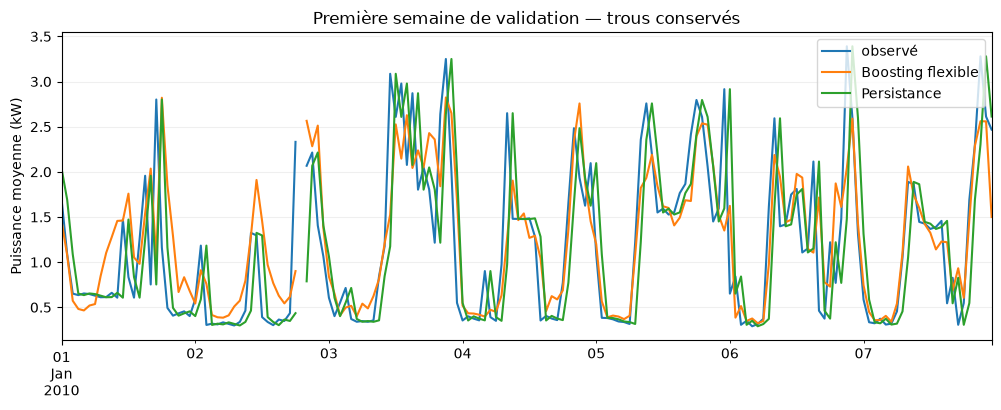

heure,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
MAE_kW,0.2208,0.1903,0.1758,0.1174,0.1273,0.1416,0.2955,0.4272,0.3799,0.3179,...,0.45,0.3942,0.4009,0.4104,0.4708,0.5515,0.5145,0.5276,0.476,0.3431
n,178.0000,178.0000,178.0000,177.0000,177.0000,177.0000,176.0000,176.0000,177.0000,177.0000,...,177.00,177.0000,175.0000,176.0000,176.0000,177.0000,178.0000,176.0000,178.000,178.0000


,MAE_kW,n
mois,,
1,0.4075,688
2,0.3925,670
3,0.3249,709
4,0.3326,719
5,0.3380,743
6,0.3274,717
12,0.2365,1


MAE sur les pointes de validation : 0.8837 kW


In [13]:
fit_idx = np.flatnonzero(train_time & usable_history & y.notna().to_numpy())
valid_idx = np.flatnonzero(valid_time & usable_history & y.notna().to_numpy())
assert y.index[fit_idx].max() <= VALID_START - DELTA
print(f"Couverture des cibles de validation : {len(valid_idx) / valid_time.sum():.2%}")

validation_predictions = pd.DataFrame({"observé": y.iloc[valid_idx]})
validation_models = {}
validation_scores = []
for name in dict.fromkeys([best_name, best_baseline_name]):
    fitted = clone(models[name])
    with threadpool_limits(limits=N_THREADS):
        fitted.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        pred = predict_nonnegative(fitted, X.iloc[valid_idx])
    validation_models[name] = fitted
    validation_predictions[name] = pred
    validation_scores.append({"modèle": name, **metrics(y.iloc[valid_idx], pred)})
validation_scores = pd.DataFrame(validation_scores).set_index("modèle")
display(validation_scores.round(4))
reference_mae = validation_scores.loc[best_baseline_name, "MAE_kW"]
validation_gain = 100 * (1 - validation_scores.loc[best_name, "MAE_kW"] / reference_mae) if reference_mae > 0 else np.nan
print(f"Gain MAE du candidat sur la référence de validation : {validation_gain:.2f} %")

plot_end = VALID_START + pd.Timedelta(days=7)
validation_predictions.loc[validation_predictions.index < plot_end].reindex(
    pd.date_range(VALID_START, plot_end, freq="h", inclusive="left")
).plot(title="Première semaine de validation — trous conservés", ylabel="Puissance moyenne (kW)")
plt.show()

diagnostics = pd.DataFrame(index=validation_predictions.index)
diagnostics["erreur"] = validation_predictions[best_name] - validation_predictions["observé"]
diagnostics["erreur_absolue"] = diagnostics["erreur"].abs()
diagnostics["heure"] = (diagnostics.index - pd.Timedelta(hours=1)).hour
diagnostics["mois"] = (diagnostics.index - pd.Timedelta(hours=1)).month
display(diagnostics.groupby("heure").agg(MAE_kW=("erreur_absolue", "mean"), n=("erreur", "size")).round(4).T)
display(diagnostics.groupby("mois").agg(MAE_kW=("erreur_absolue", "mean"), n=("erreur", "size")).round(4))
peak_threshold = y.iloc[fit_idx].quantile(0.90)  # Seuil appris sur l'entraînement.
peaks = validation_predictions["observé"] >= peak_threshold
if peaks.any():
    print("MAE sur les pointes de validation :", round(diagnostics.loc[peaks, "erreur_absolue"].mean(), 4), "kW")


**À toi — journal des expériences et décision**

Compléter ce tableau après chaque changement. Un résultat décevant reste une information utile.
Conserver les mêmes dates et le même horizon pour comparer deux expériences.

| Expérience | Une modification | MAE CV | Dispersion entre plis | MAE validation | Temps | Décision motivée |
|---|---|---|---|---|---|---|
| E01 | Références + Ridge + boosting | … | … | … | … | … |
| E02 | … | … | … | … | … | … |

**Mes conclusions de développement :** le meilleur candidat parmi ceux essayés est …
Il améliore / n'améliore pas la référence de … %. Les erreurs les plus fortes apparaissent …
La prochaine modification que je peux justifier est …


## 12 — Figer le protocole avant le test final

Avant d'activer `RUN_FINAL_TEST`, écrire sa décision dans la cellule Markdown ci-dessous.
Vérifier : horizon explicite ; origine connue ; variables historiques décalées ; transformations
apprises dans chaque entraînement ; modèles comparés sur les mêmes cibles ; métrique annoncée ;
paramètres et dates figés. Le test ne doit servir ni à choisir des paramètres, ni à décider
quel modèle présenter comme vainqueur.

La configuration et les paramètres sont enregistrés **dans les sorties du notebook**.
Sauvegarder le notebook après exécution. Le numéro de version des bibliothèques et l'empreinte
du fichier source permettront de retrouver les conditions de l'expérience.

**Ma décision finale avant ouverture du test :** modèle … ; horizon … ; raison … ;
limites déjà connues … ; date du gel …


In [14]:
# Réexécuter ce gel si un choix de développement change, avant toute ouverture du test.
FROZEN_MODEL_NAME = best_name
FROZEN_BASELINE_NAME = best_baseline_name
frozen_model = clone(models[FROZEN_MODEL_NAME])
frozen_baseline = clone(models[FROZEN_BASELINE_NAME])
with DATA_PATH.open("rb") as source:
    data_sha256 = hashlib.file_digest(source, "sha256").hexdigest()
experiment = {
    "cible": "puissance active moyenne horaire (kW), heure entièrement observée",
    "scénario": "prévisions directes répétées ; historique observé mis à jour ; modèle fixe par bloc",
    "horizon_h": HORIZON_H,
    "validation_start": str(VALID_START), "test_start": str(TEST_START),
    "final_fit_cutoff": str(final_fit_cutoff), "min_valid_minutes": MIN_VALID_MINUTES,
    "cv_folds": N_FOLDS, "cv_days": CV_DAYS,
    "métrique_sélection": "moyenne des MAE des plis", "seed": SEED,
    "modèle": FROZEN_MODEL_NAME, "référence": FROZEN_BASELINE_NAME,
    "paramètres": frozen_model.get_params(deep=True), "variables": list(X.columns),
    "data_sha256": data_sha256, "versions": versions,
}
print(json.dumps(experiment, ensure_ascii=False, indent=2, default=str))


{
  "cible": "puissance active moyenne horaire (kW), heure entièrement observée",
  "scénario": "prévisions directes répétées ; historique observé mis à jour ; modèle fixe par bloc",
  "horizon_h": 1,
  "validation_start": "2010-01-01 00:00:00",
  "test_start": "2010-07-01 00:00:00",
  "final_fit_cutoff": "2010-06-30 23:00:00",
  "min_valid_minutes": 60,
  "cv_folds": 3,
  "cv_days": 90,
  "métrique_sélection": "moyenne des MAE des plis",
  "seed": 42,
  "modèle": "Boosting flexible",
  "référence": "Persistance",
  "paramètres": {
    "categorical_features": "from_dtype",
    "early_stopping": false,
    "interaction_cst": null,
    "l2_regularization": 10.0,
    "learning_rate": 0.05,
    "loss": "squared_error",
    "max_bins": 255,
    "max_depth": null,
    "max_features": 1.0,
    "max_iter": 180,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 30,
    "monotonic_cst": null,
    "n_iter_no_change": 10,
    "quantile": null,
    "random_state": 42,
    "scoring": "loss",
    "to

## 13 — Évaluer une fois sur le test réservé

Après avoir rédigé la décision, passer `RUN_FINAL_TEST` à `True` à l'étape 1 et réexécuter
le parcours dans l'ordre. Les choix doivent rester ceux figés avant consultation du test.
Le candidat et la référence sont réentraînés avec toutes les cibles disponibles à la
première origine de test, y compris la validation admissible.

Les valeurs mesurées du test peuvent ensuite devenir des retards pour les prévisions
suivantes, uniquement lorsqu'elles sont disponibles à leur origine. Elles ne servent pas
à ajuster le modèle au cours de ce bloc. Cela reproduit le scénario annoncé à l'étape 1.

Les heures sans cible complète ne sont pas notées ; la couverture est affichée.
Ce score ne garantit pas la performance sur les longues coupures de capteur, un autre foyer,
une autre saison ou un autre horizon. Après consultation, toute nouvelle décision fondée
sur ce résultat consomme son rôle de test indépendant ; il faudra une nouvelle période réservée.


In [15]:
final_scores = None
final_predictions = None
if not RUN_FINAL_TEST:
    print("Test final réservé. Terminer les expériences et rédiger la décision de l'étape 12 avant de l'activer.")
else:
    final_fit_idx = np.flatnonzero(usable_history & (y.index <= final_fit_cutoff) & y.notna().to_numpy())
    test_idx = np.flatnonzero(usable_history & test_time & y.notna().to_numpy())
    assert y.index[final_fit_idx].max() <= TEST_START - DELTA
    assert not np.intersect1d(final_fit_idx, test_idx).size
    assert len(test_idx) > 0
    final_predictions = pd.DataFrame({"observé": y.iloc[test_idx]})
    score_rows = []
    chosen = {FROZEN_MODEL_NAME: frozen_model, FROZEN_BASELINE_NAME: frozen_baseline}
    for name, template in chosen.items():
        fitted = clone(template)
        with threadpool_limits(limits=N_THREADS):
            fitted.fit(X.iloc[final_fit_idx], y.iloc[final_fit_idx])
            pred = predict_nonnegative(fitted, X.iloc[test_idx])
        final_predictions[name] = pred
        row = {"modèle fixé avant test": name, **metrics(y.iloc[test_idx], pred)}
        if isinstance(fitted, LagReference):
            row["repli_médiane_%"] = 100 * X.iloc[test_idx][fitted.column].isna().mean()
        score_rows.append(row)
    final_scores = pd.DataFrame(score_rows).set_index("modèle fixé avant test")
    print(f"Couverture du test : {len(test_idx):,}/{test_time.sum():,} heures = {len(test_idx) / test_time.sum():.2%}")
    display(final_scores.round(4))
    ref = final_scores.loc[FROZEN_BASELINE_NAME, "MAE_kW"]
    gain = 100 * (1 - final_scores.loc[FROZEN_MODEL_NAME, "MAE_kW"] / ref) if ref > 0 else np.nan
    print(f"Gain MAE final du candidat face à la référence figée : {gain:.2f} %")
    final_predictions.iloc[:7 * 24].reindex(pd.date_range(
        final_predictions.index[0], final_predictions.iloc[:7 * 24].index[-1], freq="h"
    )).plot(title="Début du test final", ylabel="Puissance moyenne (kW)")
    plt.show()


Test final réservé. Terminer les expériences et rédiger la décision de l'étape 12 avant de l'activer.


## 14 — Rédiger le compte rendu dans ce notebook

Compléter avec les valeurs effectivement obtenues, sans inventer de score.

1. **Problème.** Je prévois … à l'instant …, avec un horizon de … et une fréquence de …
2. **Données.** Source … ; période … ; unité … ; traitement des heures incomplètes …
3. **Protection contre les fuites.** Découpage … ; règle de disponibilité … ; décalages … ;
   transformations dans les pipelines … ; distinction entre prévisions successives et prévisions simultanées …
4. **Comparaison.** Référence … ; MAE CV … ; dispersion … ; modèle retenu … ; budget de calcul …
5. **Validation.** MAE … ; RMSE … ; biais … ; erreurs par heure/mois … ; pistes étudiées …
6. **Test réservé.** Activé après gel : oui/non ; couverture … ; MAE … ; RMSE … ; gain sur la référence …
7. **Limites.** Un foyer ; hypothèse de disponibilité immédiate ; horloge sans fuseau ; heures
   incomplètes exclues ; changements d'habitudes ; autres limites constatées …

**Pour travailler efficacement :** conserver une première expérience reproductible ; privilégier
des hypothèses simples et mesurables ; annoter chaque essai ; comparer temps et précision ;
sauvegarder les sorties du notebook. Le « meilleur résultat » est le meilleur résultat honnête
parmi les configurations évaluées pour ce protocole, sans garantie d'optimum.

**Références utiles :**

- [UCI — données et attribution, Hebrail et Berard, DOI 10.24432/C58K54](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption).
- [scikit-learn — fuites de données et pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn — variables retardées et évaluation chronologique](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).
- [scikit-learn — découpage chronologique et paramètre gap](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
- [scikit-learn — Histogram Gradient Boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html).
